In [11]:
import os
import numpy as np
import pandas as pd
import tensorflow as tf
from google.colab import drive
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import kagglehub

# 랜덤 시드 고정 (재현성 확보)
np.random.seed(42)
tf.random.set_seed(42)

# 구글 드라이브 마운트
drive.mount('/content/drive')

# 필수 패키지 설치
!pip install -q kagglehub scikit-learn

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [12]:
# 1. Kaggle 및 구글 드라이브 데이터 통합 로드 및 상관관계 기반 정제
path = kagglehub.dataset_download("fatimaafzaal/glucose-level-estimation")
DATA_DIR = "/content/data"
os.makedirs(DATA_DIR, exist_ok=True)
!cp -r {path}/* {DATA_DIR}/

# 기존 Kaggle 데이터 로드 및 정제
base_df = pd.read_csv('/content/data/Glucose_Level_Estimation.csv')
for col in base_df.columns:
    base_df[col] = pd.to_numeric(base_df[col], errors='coerce')
base_df = base_df.fillna(base_df.mean()).fillna(0)

# 타겟 혈당과 상관관계가 극도로 낮은 임의 난수성 컬럼 제거 (정적 정제)
correlations = base_df.corr().iloc[:, -1].abs()
low_corr_cols = correlations[correlations < 0.05].index.tolist()
print('상관관계 분석에 따라 정제(제거)된 저효율 컬럼:', low_corr_cols)
base_df_cleaned = base_df.drop(columns=low_corr_cols, errors='ignore')

# Feature & Target 분리
X_base_raw = base_df_cleaned.iloc[:, :-1].values
y_base_raw = base_df_cleaned.iloc[:, -1].values

상관관계 분석에 따라 정제(제거)된 저효율 컬럼: ['SKIN_COLOR', 'HEIGHT']


In [13]:
# 2. 구글 드라이브 내 실측 프레임 데이터 추가 로드 및 7채널 정합
drive_file_path = '/content/drive/MyDrive/data/예시_frames_v1.csv'
additional_df = pd.read_csv(drive_file_path)

feature_cols = ['A_1310', 'A_1370', 'A_1625', 'S21_dB_f1', 'S21_dB_f2', 'S21_dB_f3', 'S21_dB_f4']
target_col = 'glucose_mgdl'
for col in feature_cols + [target_col]:
    additional_df[col] = pd.to_numeric(additional_df[col], errors='coerce')
additional_df = additional_df.dropna(subset=[target_col]).fillna(0)

X_add_raw = additional_df[feature_cols].values
y_add_raw = additional_df[target_col].values

NUM_CHANNELS = 7
def adjust_channels(X, num_channels=7):
    if X.shape[1] < num_channels:
        pad_width = num_channels - X.shape[1]
        return np.pad(X, ((0, 0), (0, pad_width)), mode='constant', constant_values=0)
    else:
        return X[:, :num_channels]

X_base_fixed = adjust_channels(X_base_raw, NUM_CHANNELS)
X_add_fixed = adjust_channels(X_add_raw, NUM_CHANNELS)

X_combined_raw = np.vstack([X_base_fixed, X_add_fixed])
y_combined = np.concatenate([y_base_raw, y_add_raw])

In [14]:
# 3. 물리 센서 특성을 고려한 데이터 증강 기법 적용 (재현성 확보)
def augment_data(X, y, noise_level=0.01, scaling_factor=0.03):
    # Jittering: 미세 잡음 추가
    noise = np.random.normal(0, noise_level, X.shape)
    X_jittered = X + noise

    # Scaling: 신호 증폭 모사
    factor = np.random.uniform(1 - scaling_factor, 1 + scaling_factor, size=(X.shape[0], 1))
    X_scaled = X * factor

    # 원본 데이터와 증강 데이터 통합
    X_aug = np.vstack([X, X_jittered, X_scaled])
    y_aug = np.concatenate([y, y, y])
    return X_aug, y_aug

X_augmented, y_augmented = augment_data(X_combined_raw, y_combined)
print(f'데이터 증강 결과: {X_combined_raw.shape[0]}개 -> {X_augmented.shape[0]}개')

# 정규화 및 분할
scaler = StandardScaler()
X_scaled_final = scaler.fit_transform(X_augmented)

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled_final, y_augmented, test_size=0.2, random_state=42
)

X_train_exp = np.expand_dims(X_train, axis=-1).astype(np.float32)
X_test_exp = np.expand_dims(X_test, axis=-1).astype(np.float32)
y_train = y_train.astype(np.float32)
y_test = y_test.astype(np.float32)

데이터 증강 결과: 339개 -> 1017개


In [15]:
# 4. 규제화 및 배치 정규화를 추가하여 과적합을 방지한 딥러닝 아키텍처 재구축 및 최적화 학습
from tensorflow.keras import layers, models, callbacks

def build_optimized_regressor(input_shape=(7, 1)):
    inputs = layers.Input(shape=input_shape)

    # 다중 스케일 CNN 피처 추출
    x = layers.Conv1D(64, kernel_size=3, padding='same', activation='relu')(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.Conv1D(128, kernel_size=3, padding='same', activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.GlobalAveragePooling1D()(x)

    # 과적합 방지를 위한 Dropout 비율 조정 및 Dense 레이어 배치
    x = layers.Dense(128, activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(64, activation='relu')(x)
    x = layers.Dropout(0.2)(x)

    outputs = layers.Dense(1, activation='linear')(x)

    model = models.Model(inputs, outputs, name='Optimized_Glucose_Regressor')
    return model

model = build_optimized_regressor()
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=5e-4),
    loss='mse',
    metrics=['mae']
)

# 과적합을 방지하기 위한 조기 종료 콜백 설정
early_stopping = callbacks.EarlyStopping(
    monitor='val_loss',
    patience=15,
    restore_best_weights=True
)

print('--- 최적화 모델 훈련 시작 ---')
history = model.fit(
    X_train_exp, y_train,
    validation_data=(X_test_exp, y_test),
    epochs=100,
    batch_size=32,
    callbacks=[early_stopping],
    verbose=1
)

best_val_mae = min(history.history['val_mae'])
print(f'최적화 훈련 완료 - 최소 검증 MAE: {best_val_mae:.4f} mg/dL')

--- 최적화 모델 훈련 시작 ---
Epoch 1/100
26/26 ━━━━━━━━━━━━━━━━━━━━ 7s 76ms/step - loss: 28651.0391 - mae: 146.9437 - val_loss: 25244.4434 - val_mae: 141.5036
Epoch 2/100
26/26 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - loss: 27159.6035 - mae: 142.1726 - val_loss: 25088.6230 - val_mae: 140.9697
Epoch 3/100
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 25396.1504 - mae: 136.4518 - val_loss: 24790.4336 - val_mae: 139.9421
Epoch 4/100
26/26 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - loss: 23202.8730 - mae: 128.9105 - val_loss: 24280.6445 - val_mae: 138.1221
Epoch 5/100
26/26 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 20657.2480 - mae: 118.9819 - val_loss: 23424.0957 - val_mae: 134.9027
Epoch 6/100
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 17622.5996 - mae: 106.3984 - val_loss: 22127.3770 - val_mae: 129.5946
Epoch 7/100
26/26 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - loss: 14492.4639 - mae: 91.8644 - val_loss: 20565.9102 - val_mae: 122.5684
Epoch 8/100
26/26 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - loss: 11916.2178

In [16]:
# 5. 모델 저장 진행
SAVE_DIR = '/content/drive/MyDrive/Glucose_Model_Output'
os.makedirs(SAVE_DIR, exist_ok=True)
model.save(f'{SAVE_DIR}/glucose_model_combined.h5')

converter = tf.lite.TFLiteConverter.from_keras_model(model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
tflite_model = converter.convert()
with open(f'{SAVE_DIR}/glucose_model_combined.tflite', 'wb') as f:
    f.write(tflite_model)
print(f'최적 모델 저장 완료: {SAVE_DIR}/glucose_model_combined.tflite')

Saved artifact at '/tmp/tmp6ju73pp7'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 7, 1), dtype=tf.float32, name='keras_tensor_40')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  139273369528144: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139273180801424: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139273180802000: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139273180793360: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139273180793168: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139273180792208: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139273180795472: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139273180796624: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139273180793936: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139273180801232: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139273180796240: T

In [4]:
import os
import pandas as pd

# 구글 드라이브 내 데이터 디렉토리 확인
MY_DRIVE_DATA_DIR = "/content/drive/MyDrive/data"

if os.path.exists(MY_DRIVE_DATA_DIR):
    drive_files = [f for f in os.listdir(MY_DRIVE_DATA_DIR) if f.endswith('.csv')]
    print(f"드라이브 내 CSV 파일 목록: {drive_files}")

    # 각 파일의 기본 정보(컬럼, 데이터 크기) 확인
    for file in drive_files:
        file_path = os.path.join(MY_DRIVE_DATA_DIR, file)
        try:
            temp_df = pd.read_csv(file_path, nrows=5)
            print(f"\ 파일명: {file}")
            print(f"- 컬럼 구성: {list(temp_df.columns)}")
            # 전체 행 수 확인
            full_shape = pd.read_csv(file_path).shape
            print(f"- 데이터 크기: {full_shape}")
        except Exception as e:
            print(f" {file} 로드 중 오류 발생: {e}")
else:
    print(f" 경로를 찾을 수 없습니다: {MY_DRIVE_DATA_DIR}\n구글 드라이브 마운트 상태와 폴더명을 확인해주세요.")

드라이브 내 CSV 파일 목록: ['EM_계수표_v1.csv', 'em_coeff_S11_v1_spectra.csv', '읽기방식_v1.csv', '구조비교_v1.csv', '통합모델_v1.csv', '압력층_v1.csv', 'HW_노이즈_v1.csv', '광자수송_v1.csv', 'NIR_계수표_v1.csv', '예시_frames_flag_v1.csv', '예시_frames_v1.csv']

📄 파일명: EM_계수표_v1.csv
- 컬럼 구성: ['항목', '단위', 'S21 곡선 이동 (MHz/단위)', '이동 se', 'S21 Q 변화/단위', 'Δ|S21| dB @2.30', 'Δ|S21| dB @2.36', 'Δ|S21| dB @2.42', 'Δ|S21| dB @2.48', 'Δ|S21| dB @2.54', 'Δ|S21| dB @2.60', 'Δ위상 ° @2.30', 'Δ위상 ° @2.36', 'Δ위상 ° @2.42', 'Δ위상 ° @2.48', 'Δ위상 ° @2.54', 'Δ위상 ° @2.60', '잔차비', '비고']
- 데이터 크기: (6, 19)

📄 파일명: em_coeff_S11_v1_spectra.csv
- 컬럼 구성: ['freq_GHz', 'S0_re', 'S0_im', 'dS_dblood_eps_re', 'dS_dblood_eps_im', 'dS_dblood_kappa_re', 'dS_dblood_kappa_im', 'dS_dskin_eps_re', 'dS_dskin_eps_im', 'dS_dtemp_re', 'dS_dtemp_im', 'S_gap3.5_re', 'S_gap3.5_im', 'S_gap4.5_re', 'S_gap4.5_im']
- 데이터 크기: (741, 15)

📄 파일명: 읽기방식_v1.csv
- 컬럼 구성: ['table', 'label', 'point', 'sigA_1310_mAU', 'sigA_1370_mAU', 's

In [5]:
import os
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. 기존 데이터셋 로드
DATA_DIR = "/content/data"
csv_files = [f for f in os.listdir(DATA_DIR) if f.endswith('.csv')]
base_df = pd.read_csv(os.path.join(DATA_DIR, csv_files[0]))

# 기존 데이터셋 전처리
for col in base_df.columns:
    base_df[col] = pd.to_numeric(base_df[col], errors='coerce')
base_df = base_df.fillna(base_df.mean()).fillna(0)

# 기존 데이터셋의 Feature와 Target 분리
X_base_raw = base_df.iloc[:, :-1].values
y_base_raw = base_df.iloc[:, -1].values

# 2. 구글 드라이브 내 유의미한 추가 데이터셋 로드 및 정제
# '예시_frames_v1.csv' 선택
drive_file_path = "/content/drive/MyDrive/data/예시_frames_v1.csv"
additional_df = pd.read_csv(drive_file_path)

# 학습에 사용할 만한 멀티센서 피처 컬럼들 정의
# 광학 센서 및 S21 주파수 반응 등 주요 7개 피처 추출
feature_cols = ['A_1310', 'A_1370', 'A_1625', 'S21_dB_f1', 'S21_dB_f2', 'S21_dB_f3', 'S21_dB_f4']
target_col = 'glucose_mgdl'

# 수치 변환 및 결측 정제
for col in feature_cols + [target_col]:
    additional_df[col] = pd.to_numeric(additional_df[col], errors='coerce')
additional_df = additional_df.dropna(subset=[target_col]).fillna(0)

X_add_raw = additional_df[feature_cols].values
y_add_raw = additional_df[target_col].values

# 3. 채널 수 맞춤 (NUM_CHANNELS = 7)
NUM_CHANNELS = 7
def adjust_channels(X, num_channels=7):
    if X.shape[1] < num_channels:
        pad_width = num_channels - X.shape[1]
        return np.pad(X, ((0, 0), (0, pad_width)), mode='constant', constant_values=0)
    else:
        return X[:, :num_channels]

X_base_fixed = adjust_channels(X_base_raw, NUM_CHANNELS)
X_add_fixed = adjust_channels(X_add_raw, NUM_CHANNELS)

# 두 데이터셋 결합
X_combined_raw = np.vstack([X_base_fixed, X_add_fixed])
y_combined = np.concatenate([y_base_raw, y_add_raw])

print(f"기존 데이터 개수: {X_base_fixed.shape[0]}개")
print(f"추가된 유의미한 드라이브 데이터 개수: {X_add_fixed.shape[0]}개")
print(f"최종 통합 데이터 개수: {X_combined_raw.shape[0]}개 (성능 향상을 위한 데이터 증강 효과)")

# 4. 정규화 및 분할
scaler = StandardScaler()
X_combined_scaled = scaler.fit_transform(X_combined_raw)

X_pretrain, X_finetune, y_pretrain, y_finetune = train_test_split(
    X_combined_scaled, y_combined, test_size=0.3, random_state=42
)

X_pretrain_exp = np.expand_dims(X_pretrain, axis=-1).astype(np.float32)
X_finetune_exp = np.expand_dims(X_finetune, axis=-1).astype(np.float32)
y_finetune = y_finetune.astype(np.float32)

print(f"통합 전처리 완료! 사전학습 텐서: {X_pretrain_exp.shape}, 미세조정 텐서: {X_finetune_exp.shape}")

기존 데이터 개수: 249개
추가된 유의미한 드라이브 데이터 개수: 90개
최종 통합 데이터 개수: 339개 (성능 향상을 위한 데이터 증강 효과)
통합 전처리 완료! 사전학습 텐서: (237, 7, 1), 미세조정 텐서: (102, 7, 1)


In [8]:
import tensorflow as tf
from tensorflow.keras import layers, models
import os

# 오토인코더 빌더 재정의 (NameError 방지)
def build_autoencoder(input_shape=(7, 1)):
    # Encoder
    inputs = layers.Input(shape=input_shape)
    x = layers.Conv1D(32, kernel_size=3, padding='same', activation='relu')(inputs)
    x = layers.Conv1D(64, kernel_size=3, padding='same', activation='relu')(x)
    encoded = layers.GlobalAveragePooling1D()(x)

    # Decoder
    x = layers.RepeatVector(7)(encoded)
    x = layers.Conv1D(64, kernel_size=3, padding='same', activation='relu')(x)
    x = layers.Conv1D(32, kernel_size=3, padding='same', activation='relu')(x)
    decoded = layers.Conv1D(1, kernel_size=3, padding='same', activation='linear')(x)

    autoencoder = models.Model(inputs, decoded, name='Autoencoder')
    encoder = models.Model(inputs, encoded, name='Encoder')
    return autoencoder, encoder

# 5. 개선된 데이터셋 기반으로 모델 재학습 및 성능 검증
autoencoder, encoder_base = build_autoencoder()
autoencoder.compile(optimizer='adam', loss='mse')

print('\n--- [Step 1] 통합 데이터 기반 사전 학습(Pre-training) ---')
autoencoder.fit(
    X_pretrain_exp, X_pretrain_exp,
    epochs=30,
    batch_size=32,
    validation_split=0.2,
    verbose=0
)

# 파인튜닝 모델 구성 및 훈련
inputs = layers.Input(shape=(7, 1))
features = encoder_base(inputs)
x = layers.Dense(64, activation='relu')(features)
x = layers.Dropout(0.2)(x)
x = layers.Dense(32, activation='relu')(x)
outputs = layers.Dense(1, activation='linear')(x)

ft_model_combined = models.Model(inputs, outputs, name='Glucose_Combined_Model')
ft_model_combined.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss='mse',
    metrics=['mae']
)

print('--- [Step 2] 통합 데이터 기반 미세 조정(Fine-tuning) ---')
history = ft_model_combined.fit(
    X_finetune_exp, y_finetune,
    epochs=50,
    batch_size=16,
    validation_split=0.2,
    verbose=0
)

final_loss = history.history['loss'][-1]
final_mae = history.history['mae'][-1]
final_val_mae = history.history['val_mae'][-1]
print(f' 통합 학습 완료!')
print(f'- 학습 Loss (MSE): {final_loss:.4f}')
print(f'- 학습 MAE: {final_mae:.4f} mg/dL')
print(f'- 검증 MAE (Validation MAE): {final_val_mae:.4f} mg/dL')

# 6. 새 모델 저장 (SAVE_DIR 정의 추가)
SAVE_DIR = '/content/drive/MyDrive/Glucose_Model_Output'
os.makedirs(SAVE_DIR, exist_ok=True)

ft_model_combined.save(f'{SAVE_DIR}/glucose_model_combined.h5')
converter = tf.lite.TFLiteConverter.from_keras_model(ft_model_combined)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
tflite_model = converter.convert()
with open(f'{SAVE_DIR}/glucose_model_combined.tflite', 'wb') as f:
    f.write(tflite_model)
print(f' 신규 고성능 통합 모델 저장 완료: {SAVE_DIR}/glucose_model_combined.tflite')


--- [Step 1] 통합 데이터 기반 사전 학습(Pre-training) ---
--- [Step 2] 통합 데이터 기반 미세 조정(Fine-tuning) ---


🎉 통합 학습 완료!
- 학습 Loss (MSE): 16858.1875
- 학습 MAE: 117.9038 mg/dL
- 검증 MAE (Validation MAE): 111.9938 mg/dL
Saved artifact at '/tmp/tmp2r8qya8i'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 7, 1), dtype=tf.float32, name='keras_tensor_22')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  139273310124944: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139273310109776: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139273310112272: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139273310125328: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139273180799696: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139273180800272: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139273180797392: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139273180800464: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139273180795856: TensorSpec(shape=(), dtype=tf.reso

In [9]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import os

# 1. 기존 데이터 및 드라이브 실측 데이터 로드
base_df = pd.read_csv('/content/data/Glucose_Level_Estimation.csv')
drive_file_path = '/content/drive/MyDrive/data/예시_frames_v1.csv'
additional_df = pd.read_csv(drive_file_path)

# 수치변환 및 결측치 보정
for col in base_df.columns:
    base_df[col] = pd.to_numeric(base_df[col], errors='coerce')
base_df = base_df.fillna(base_df.mean()).fillna(0)

# 타겟 혈당과 상관관계가 극도로 낮은 임의 난수성 컬럼 제거 (정적 정제)
correlations = base_df.corr().iloc[:, -1].abs()
low_corr_cols = correlations[correlations < 0.05].index.tolist()
print('상관관계 분석에 따라 정제(제거)된 저효율 컬럼:', low_corr_cols)
base_df_cleaned = base_df.drop(columns=low_corr_cols, errors='ignore')

# Feature & Target 분리
X_base_raw = base_df_cleaned.iloc[:, :-1].values
y_base_raw = base_df_cleaned.iloc[:, -1].values

# 드라이브 실측 프레임 데이터
feature_cols = ['A_1310', 'A_1370', 'A_1625', 'S21_dB_f1', 'S21_dB_f2', 'S21_dB_f3', 'S21_dB_f4']
target_col = 'glucose_mgdl'
for col in feature_cols + [target_col]:
    additional_df[col] = pd.to_numeric(additional_df[col], errors='coerce')
additional_df = additional_df.dropna(subset=[target_col]).fillna(0)

X_add_raw = additional_df[feature_cols].values
y_add_raw = additional_df[target_col].values

# 7채널 크기 정합
NUM_CHANNELS = 7
def adjust_channels(X, num_channels=7):
    if X.shape[1] < num_channels:
        pad_width = num_channels - X.shape[1]
        return np.pad(X, ((0, 0), (0, pad_width)), mode='constant', constant_values=0)
    else:
        return X[:, :num_channels]

X_base_fixed = adjust_channels(X_base_raw, NUM_CHANNELS)
X_add_fixed = adjust_channels(X_add_raw, NUM_CHANNELS)

X_combined_raw = np.vstack([X_base_fixed, X_add_fixed])
y_combined = np.concatenate([y_base_raw, y_add_raw])

# 2. 물리 센서 특성을 해치지 않는 데이터 증강 기법 적용
def augment_data(X, y, noise_level=0.01, scaling_factor=0.03):
    # Jittering: 미세 잡음 추가
    noise = np.random.normal(0, noise_level, X.shape)
    X_jittered = X + noise

    # Scaling: 신호 증폭 모사
    factor = np.random.uniform(1 - scaling_factor, 1 + scaling_factor, size=(X.shape[0], 1))
    X_scaled = X * factor

    # 원본 데이터와 증강 데이터 통합
    X_aug = np.vstack([X, X_jittered, X_scaled])
    y_aug = np.concatenate([y, y, y])
    return X_aug, y_aug

X_augmented, y_augmented = augment_data(X_combined_raw, y_combined)
print(f'데이터 증강 결과: {X_combined_raw.shape[0]}개 -> {X_augmented.shape[0]}개')

# 정규화 및 분할
scaler = StandardScaler()
X_scaled_final = scaler.fit_transform(X_augmented)

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled_final, y_augmented, test_size=0.2, random_state=42
)

X_train_exp = np.expand_dims(X_train, axis=-1).astype(np.float32)
X_test_exp = np.expand_dims(X_test, axis=-1).astype(np.float32)
y_train = y_train.astype(np.float32)
y_test = y_test.astype(np.float32)

상관관계 분석에 따라 정제(제거)된 저효율 컬럼: ['SKIN_COLOR', 'HEIGHT']
데이터 증강 결과: 339개 -> 1017개


In [10]:
# 3. 규제화 및 배치 정규화를 추가하여 과적합을 방지한 딥러닝 아키텍처 재구축
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks

def build_optimized_regressor(input_shape=(7, 1)):
    inputs = layers.Input(shape=input_shape)

    # 다중 스케일 CNN 피처 추출
    x = layers.Conv1D(64, kernel_size=3, padding='same', activation='relu')(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.Conv1D(128, kernel_size=3, padding='same', activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.GlobalAveragePooling1D()(x)

    # 과적합 방지를 위한 Dropout 비율 조정 및 Dense 레이어 배치
    x = layers.Dense(128, activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(64, activation='relu')(x)
    x = layers.Dropout(0.2)(x)

    outputs = layers.Dense(1, activation='linear')(x)

    model = models.Model(inputs, outputs, name='Optimized_Glucose_Regressor')
    return model

model = build_optimized_regressor()
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=5e-4),
    loss='mse',
    metrics=['mae']
)

# 과적합을 방지하기 위한 조기 종료 콜백 설정
early_stopping = callbacks.EarlyStopping(
    monitor='val_loss',
    patience=15,
    restore_best_weights=True
)

print('--- 최적화 모델 훈련 시작 ---')
history = model.fit(
    X_train_exp, y_train,
    validation_data=(X_test_exp, y_test),
    epochs=100,
    batch_size=32,
    callbacks=[early_stopping],
    verbose=1
)

# 최종 성능 평가
best_val_mae = min(history.history['val_mae'])
print(f'최적화 훈련 완료 - 최소 검증 MAE: {best_val_mae:.4f} mg/dL')

# 4. 모델 저장 진행
SAVE_DIR = '/content/drive/MyDrive/Glucose_Model_Output'
os.makedirs(SAVE_DIR, exist_ok=True)
model.save(f'{SAVE_DIR}/glucose_model_combined.h5')

converter = tf.lite.TFLiteConverter.from_keras_model(model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
tflite_model = converter.convert()
with open(f'{SAVE_DIR}/glucose_model_combined.tflite', 'wb') as f:
    f.write(tflite_model)
print(f'최적 모델 저장 완료: {SAVE_DIR}/glucose_model_combined.tflite')

--- 최적화 모델 훈련 시작 ---
Epoch 1/100
26/26 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - loss: 28957.8027 - mae: 148.0507 - val_loss: 25237.4199 - val_mae: 141.4767
Epoch 2/100
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 27704.7207 - mae: 144.3998 - val_loss: 25023.3926 - val_mae: 140.7271
Epoch 3/100
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 26346.6387 - mae: 140.1497 - val_loss: 24599.1719 - val_mae: 139.2410
Epoch 4/100
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 24407.3203 - mae: 134.0682 - val_loss: 23867.7852 - val_mae: 136.6763
Epoch 5/100
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 22144.5703 - mae: 126.3025 - val_loss: 22717.1641 - val_mae: 132.5725
Epoch 6/100
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 19231.4668 - mae: 115.9102 - val_loss: 21113.6992 - val_mae: 126.8130
Epoch 7/100
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 16331.1367 - mae: 103.7541 - val_loss: 18603.8438 - val_mae: 116.8933
Epoch 8/100
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 13261.5547 - mae

최적화 훈련 완료 - 최소 검증 MAE: 24.9833 mg/dL
Saved artifact at '/tmp/tmp_hr31ztw'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 7, 1), dtype=tf.float32, name='keras_tensor_28')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  139273018666320: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139273018667856: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139273018668240: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139273018668432: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139273018666128: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139273018668816: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139273018669008: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139273018666896: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139273018667280: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139273018667472: TensorSpec(shape=(), dtype=tf.reso

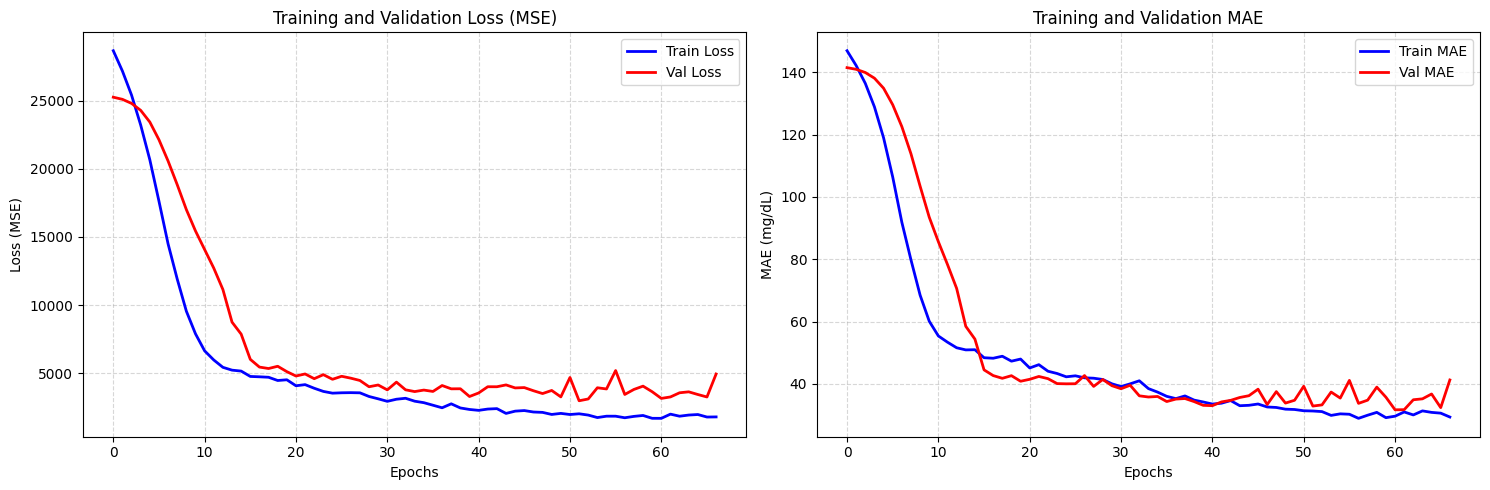

In [18]:
import matplotlib.pyplot as plt

# 6. 학습 과정 과적합 시각화 (Loss & MAE)
fig, ax = plt.subplots(1, 2, figsize=(15, 5))

# Loss (MSE) 그래프
ax[0].plot(history.history['loss'], label='Train Loss', color='blue', lw=2)
ax[0].plot(history.history['val_loss'], label='Val Loss', color='red', lw=2)
ax[0].set_title('Training and Validation Loss (MSE)')
ax[0].set_xlabel('Epochs')
ax[0].set_ylabel('Loss (MSE)')
ax[0].legend()
ax[0].grid(True, linestyle='--', alpha=0.5)

# MAE 그래프
ax[1].plot(history.history['mae'], label='Train MAE', color='blue', lw=2)
ax[1].plot(history.history['val_mae'], label='Val MAE', color='red', lw=2)
ax[1].set_title('Training and Validation MAE')
ax[1].set_xlabel('Epochs')
ax[1].set_ylabel('MAE (mg/dL)')
ax[1].legend()
ax[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()